In [1]:
import re

import emoji
import huspacy
import matplotlib.pyplot as plt
import nltk
import pandas as pd
import requests
import seaborn as sns

# Regex patterns
URL_PATTERN = r"(?i)(?:https?://|www\.)[^\s<>]+"
MENTION_PATTERN = r"(?<![\w@])@[\w.]+"
ACCENT_PATTERN = r"[áéíóöőúüűÁÉÍÓÖŐÚÜŰ]"
REPEAT_PATTERN = re.compile(r"(.)\1{2,}", re.UNICODE)

huspacy.load("hu_core_news_lg")
nltk.download("stopwords")

df = pd.read_parquet(
    "hf://datasets/magyar-nlp-szine-java/youtube/data/train-00000-of-00001.parquet"
)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\antal\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## EDA

In [2]:
df.sample(5).head()

,video_id,channel_title,text,token_count,source_id,chunk_id
172681,1y1d8GLPtJ4,JÓLVANEZÍGY,"@Zalán-x6t kérdés még számomra, hogy a tér aku...",53,168618,yt_168618_0
177925,-rj6sfGBVNA,JÓLVANEZÍGY,A “hölgyeim” és az “uraim” is többes szám. Ehh...,29,173818,yt_173818_0
611966,8WEtxJ4-sh4,TLCVEVO,Jesus this video is much darker than I remembe...,18,635947,yt_635947_0
176011,fDHjS-s7p0M,JÓLVANEZÍGY,/s,2,171883,yt_171883_1
570669,yqyIaNWP0T0,PaulaAbdulVEVO,The shalow now ❤❤❤❤❤❤❤❤❤❤❤❤❤❤❤,35,585919,yt_585919_0


In [3]:
df.info(show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 629767 entries, 0 to 629766
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   video_id       629767 non-null  str  
 1   channel_title  629767 non-null  str  
 2   text           629767 non-null  str  
 3   token_count    629767 non-null  int64
 4   source_id      629767 non-null  int64
 5   chunk_id       629767 non-null  str  
dtypes: int64(2), str(4)
memory usage: 136.8 MB


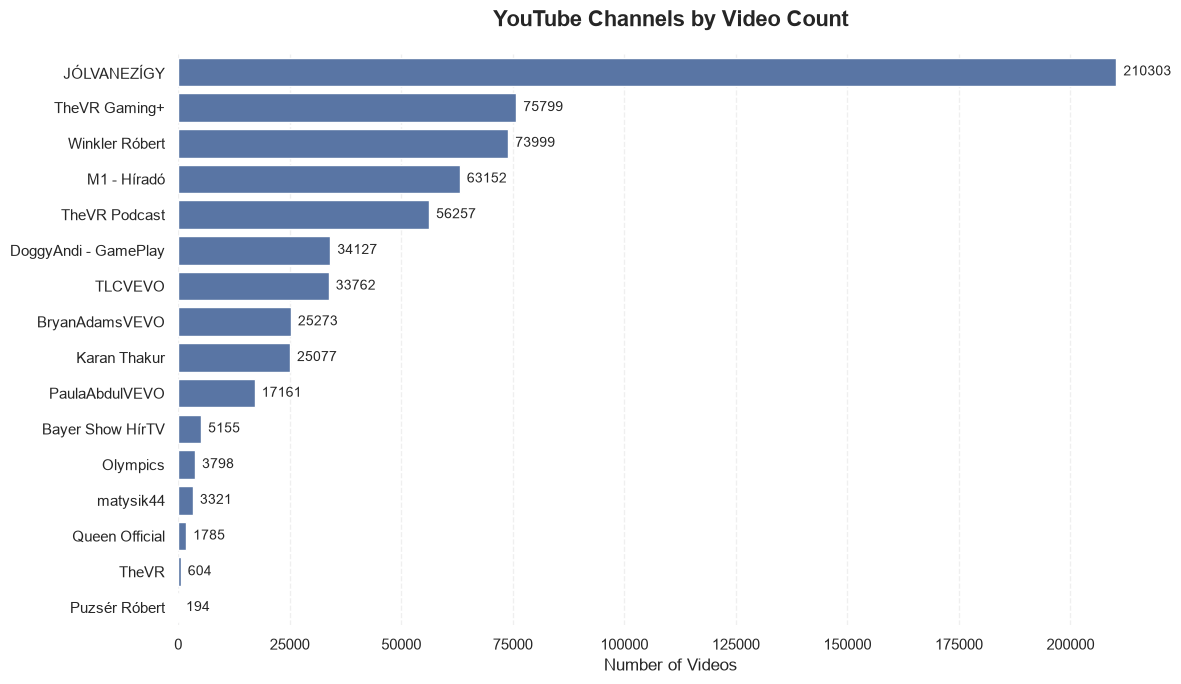

In [4]:
counts = df["channel_title"].value_counts()

sns.set_theme(style="whitegrid", context="notebook")

fig, ax = plt.subplots(figsize=(12, 7))

sns.barplot(
    x=counts.values,
    y=counts.index,
    ax=ax
)

# Value labels
for container in ax.containers:
    ax.bar_label(container, padding=5, fontsize=10)

# Formatting
ax.set_title(
    "YouTube Channels by Video Count",
    fontsize=16,
    fontweight="bold",
    pad=20
)
ax.set_xlabel("Number of Videos", fontsize=12)
ax.set_ylabel("")


ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

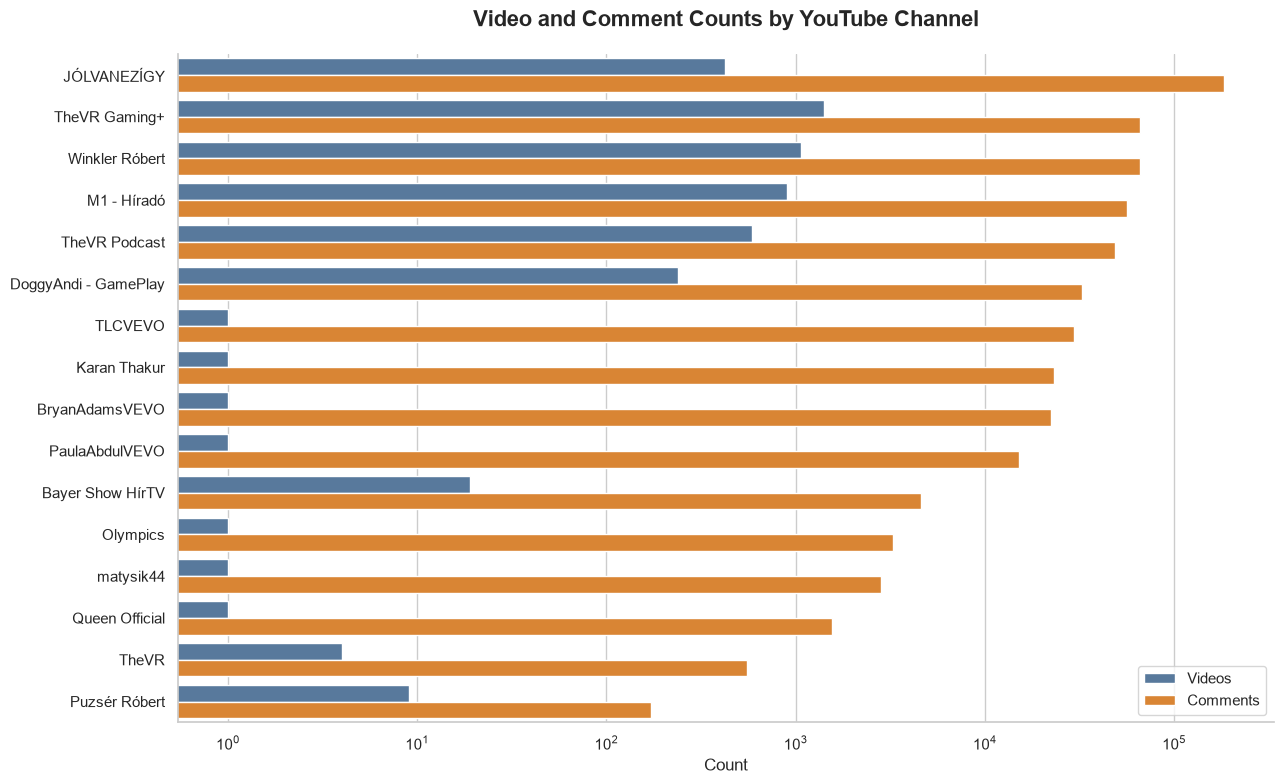

In [5]:
# Count unique videos and comments per channel
channel_stats = (
    df.groupby("channel_title")
    .agg(
        video_count=("video_id", "nunique"),
        comment_count=("source_id", "nunique")
    )
    .sort_values("comment_count", ascending=False)
    .reset_index()
)

# Convert to long format for Seaborn
plot_df = channel_stats.melt(
    id_vars="channel_title",
    value_vars=["video_count", "comment_count"],
    var_name="Metric",
    value_name="Count"
)

plot_df["Metric"] = plot_df["Metric"].map({
    "video_count": "Videos",
    "comment_count": "Comments"
})

# Plot
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(13, 8))

sns.barplot(
    data=plot_df,
    x="Count",
    y="channel_title",
    hue="Metric",
    palette={"Videos": "#4C78A8", "Comments": "#F58518"},
    order=channel_stats["channel_title"],
    ax=ax
)

ax.set_title(
    "Video and Comment Counts by YouTube Channel",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Count")
ax.set_ylabel("")
ax.legend(title="")
ax.set_xscale("log")

sns.despine()
plt.tight_layout()
plt.show()

In [6]:
# Másolat létrehozása
df_chunks = df.copy()

# Chunk sorszámának kinyerése
# pl. yt_460946_2 -> 2
df_chunks["chunk_order"] = (
    df_chunks["chunk_id"]
    .str.extract(r"_(\d+)$")[0]
    .astype(int)
)

# Rendezés eredeti komment és chunk-sorrend alapján
df_chunks = df_chunks.sort_values(
    ["source_id", "chunk_order"]
)

# Eredeti kommentek rekonstruálása
df_comments = (
    df_chunks.groupby(["video_id", "source_id"], as_index=False)
    .agg(
        channel_title=("channel_title", "first"),
        text=("text", lambda x: " ".join(x.dropna().str.strip())),
        chunk_count=("chunk_id", "count")
    )
)

display(df_comments.head())

,video_id,source_id,channel_title,text,chunk_count
0,--8xn2FkAA0,348745,TheVR Gaming+,Megosztott linkek:\r\n\r\n26:25 - Durva buzdít...,1
1,--8xn2FkAA0,348746,TheVR Gaming+,Kicsit durva csak. Mint az is hogy sokan az ol...,1
2,--8xn2FkAA0,348747,TheVR Gaming+,Talán sikeresebb lehetne az oltás népszerűsíté...,1
3,--8xn2FkAA0,348748,TheVR Gaming+,"@egyresztmasreszt4292 jó, de ugye ő konteós la...",1
4,--8xn2FkAA0,348749,TheVR Gaming+,@egyresztmasreszt4292 milyen Robi? Szkeptikus ...,1


In [7]:
import pandas as pd
import spacy

plot_df = df_comments.copy()
plot_df["text"] = plot_df["text"].fillna("").astype(str)

# Character count
plot_df["char_count"] = plot_df["text"].str.len()

# Hungarian tokenization
nlp = spacy.blank("hu")

plot_df["token_count"] = [
    sum(not token.is_space for token in doc)
    for doc in nlp.pipe(plot_df["text"], batch_size=1000)
]

display(plot_df[["channel_title", "char_count", "token_count"]].head())

,channel_title,char_count,token_count
0,TheVR Gaming+,159,12
1,TheVR Gaming+,245,49
2,TheVR Gaming+,347,57
3,TheVR Gaming+,64,9
4,TheVR Gaming+,76,8


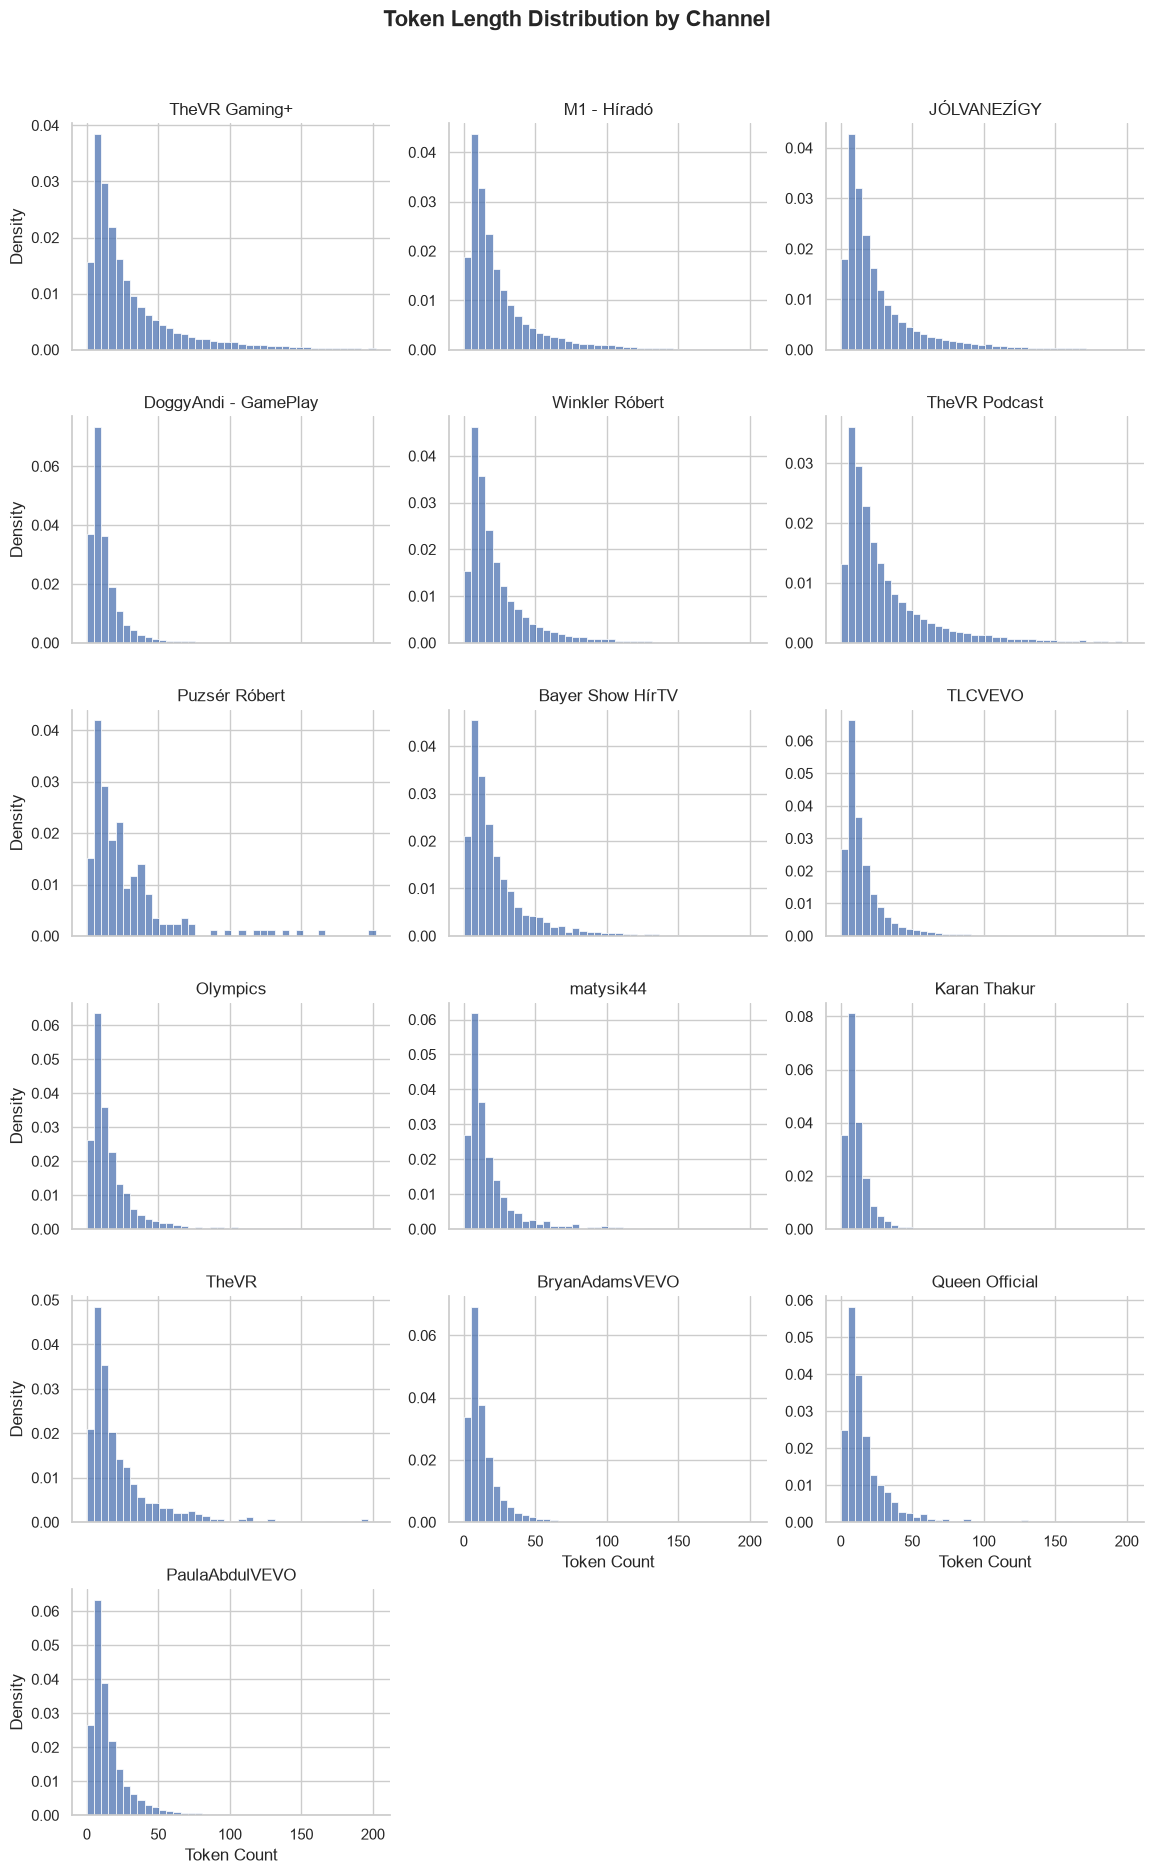

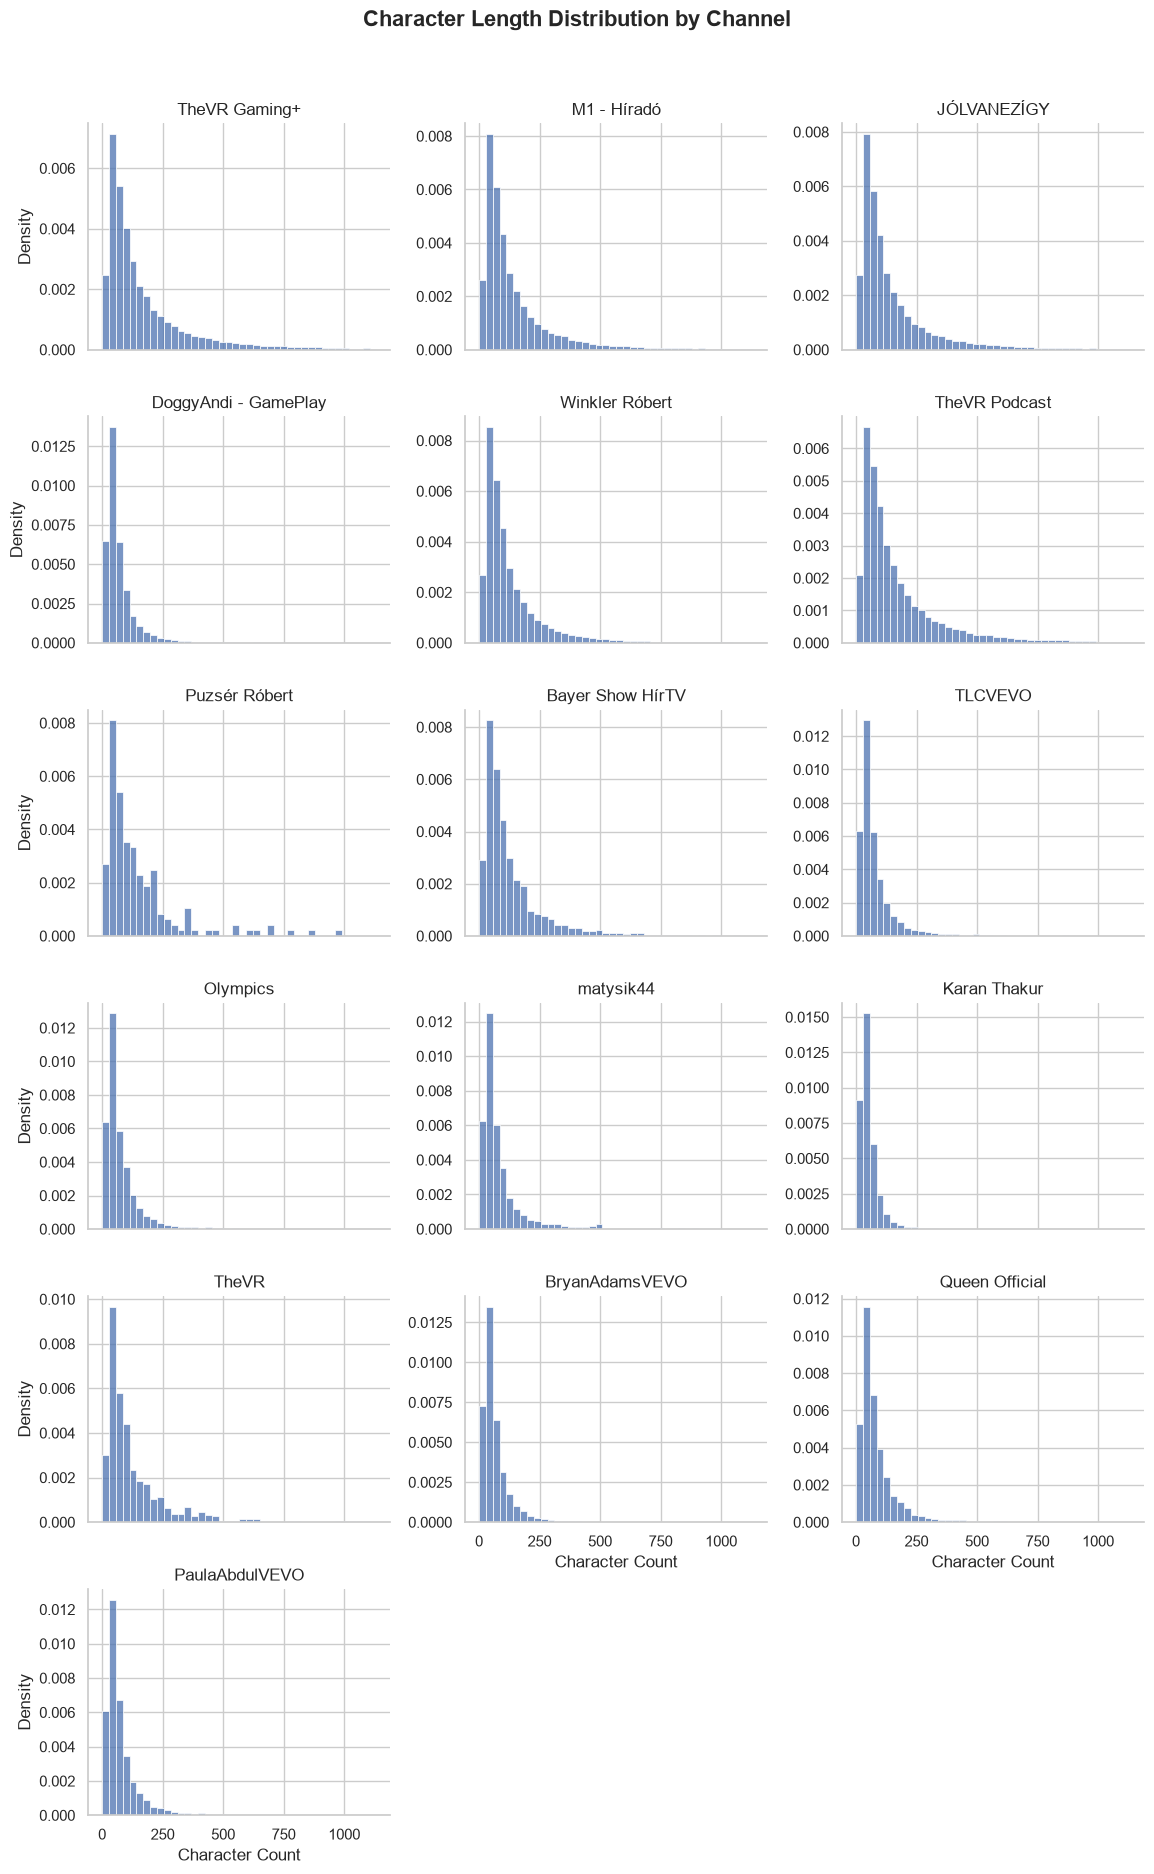

In [8]:
# Top 6 channels by comment count
top_channels = (
    plot_df["channel_title"]
    .value_counts()
    .index
)

channel_df = plot_df[
    plot_df["channel_title"].isin(top_channels)
].copy()

# Plot token and character distributions
for metric, label in [
    ("token_count", "Token"),
    ("char_count", "Character")
]:
    limit = plot_df[metric].quantile(0.99)
    data = channel_df[channel_df[metric] <= limit]

    g = sns.displot(
        data=data,
        x=metric,
        col="channel_title",
        col_wrap=3,
        bins=40,
        binrange=(0, max(1, limit)),
        stat="density",
        common_norm=False,
        height=3,
        aspect=1.3,
        facet_kws={"sharex": True, "sharey": False}
    )

    g.set_axis_labels(f"{label} Count", "Density")
    g.set_titles("{col_name}")
    g.figure.suptitle(
        f"{label} Length Distribution by Channel",
        fontsize=16,
        fontweight="bold",
        y=1.04
    )

    plt.show()

In [9]:
import emoji

# Preferably use the reconstructed, not yet filtered comments
df_features = df_comments.copy()
df_features["text"] = df_features["text"].fillna("").astype(str)

# Regex patterns
URL_PATTERN = r"(?i)(?:https?://|www\.)[^\s<>]+"
MENTION_PATTERN = r"(?<![\w@])@[\w.]+"
ACCENT_PATTERN = r"[áéíóöőúüűÁÉÍÓÖŐÚÜŰ]"

# 1. Contains emoji
df_features["has_emoji"] = df_features["text"].map(
    lambda text: emoji.emoji_count(text) > 0
)

# 2. Contains URL
df_features["has_link"] = (
    df_features["text"].str.contains(URL_PATTERN, regex=True)
)

# 3. Contains @mention
# Remove URLs first to avoid counting @ inside links
text_no_urls = df_features["text"].str.replace(
    URL_PATTERN, " ", regex=True
)

df_features["has_mention"] = text_no_urls.str.contains(
    MENTION_PATTERN, regex=True
)

# 4. Candidate accentless Hungarian text
# Remove URLs and mentions before counting words
text_content = text_no_urls.str.replace(
    MENTION_PATTERN, " ", regex=True
)

word_count = text_content.str.findall(r"[^\W\d_]+").str.len()

df_features["accentless_candidate"] = (
    (word_count >= 3)
    & ~text_content.str.contains(ACCENT_PATTERN, regex=True)
)

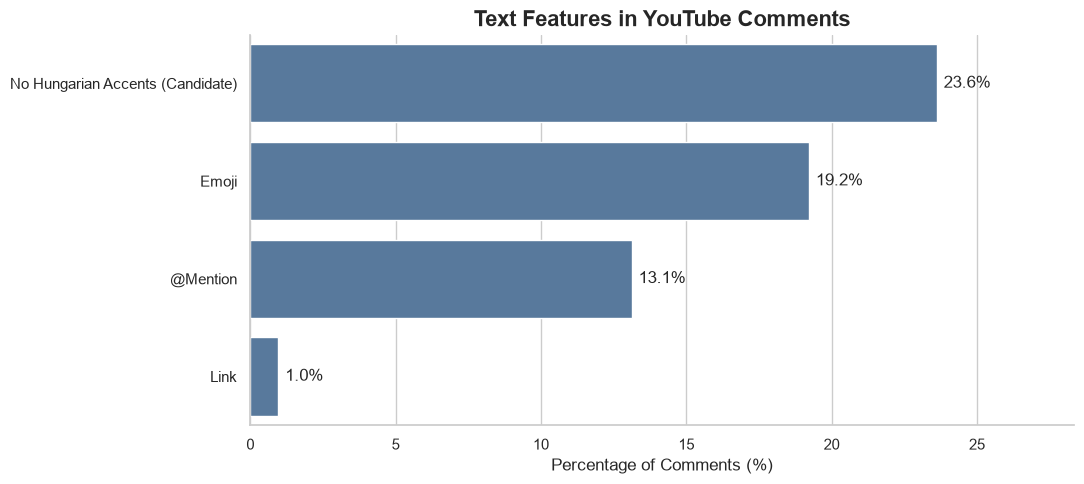

In [10]:
features = {
    "has_emoji": "Emoji",
    "has_link": "Link",
    "has_mention": "@Mention",
    "accentless_candidate": "No Hungarian Accents (Candidate)"
}

# Calculate proportions
feature_stats = (
    df_features[list(features)]
    .mean()
    .mul(100)
    .rename(index=features)
    .sort_values(ascending=False)
    .reset_index()
)

feature_stats.columns = ["Feature", "Percentage"]

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(11, 5))

sns.barplot(
    data=feature_stats,
    x="Percentage",
    y="Feature",
    color="#4C78A8",
    ax=ax
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=5
    )

ax.set_title(
    "Text Features in YouTube Comments",
    fontsize=16,
    fontweight="bold"
)
ax.set_xlabel("Percentage of Comments (%)")
ax.set_ylabel("")
ax.set_xlim(0, max(5, feature_stats["Percentage"].max() * 1.2))

sns.despine()
plt.tight_layout()
plt.show()

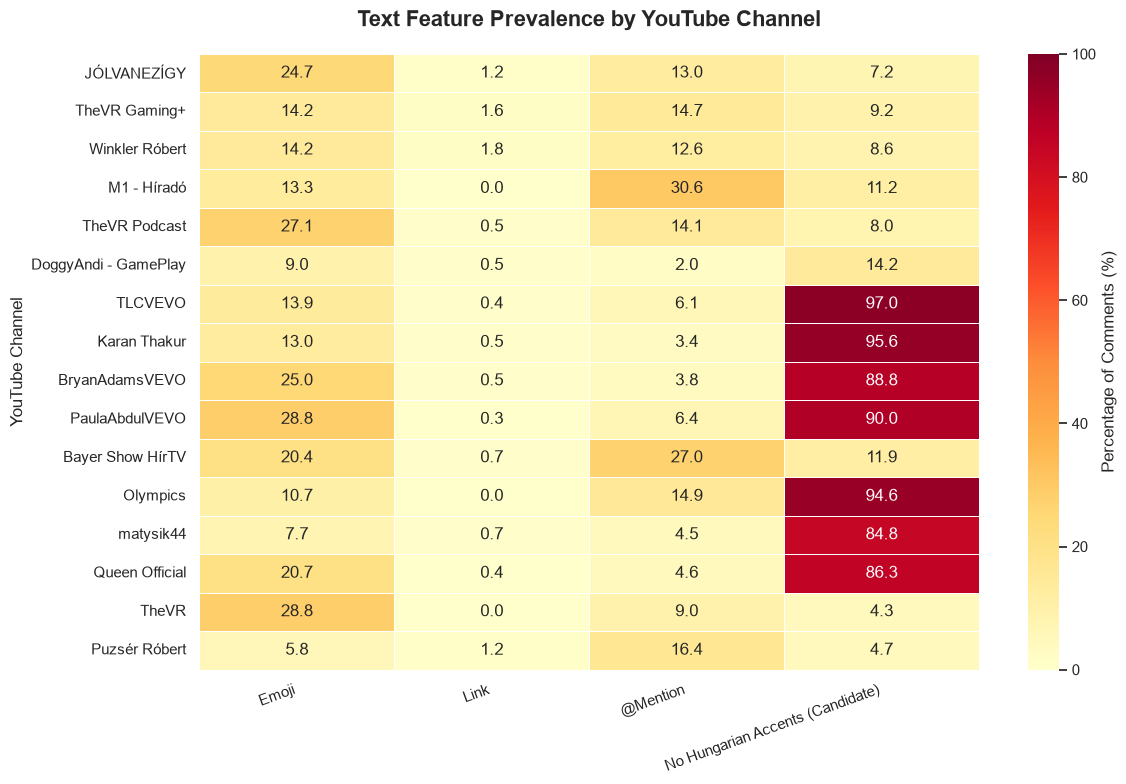

In [11]:
# Top 12 channels by number of comments
top_channels = (
    df_features["channel_title"]
    .value_counts()
    .index
)

# Calculate feature percentages by channel
channel_features = (
    df_features[
        df_features["channel_title"].isin(top_channels)
    ]
    .groupby("channel_title")[list(features)]
    .mean()
    .mul(100)
    .rename(columns=features)
    .reindex(top_channels)
)

plt.figure(figsize=(12, 8))

sns.heatmap(
    channel_features,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={"label": "Percentage of Comments (%)"}
)

plt.title(
    "Text Feature Prevalence by YouTube Channel",
    fontsize=16,
    fontweight="bold",
    pad=20
)
plt.xlabel("")
plt.ylabel("YouTube Channel")
plt.xticks(rotation=20, ha="right")

plt.tight_layout()
plt.show()

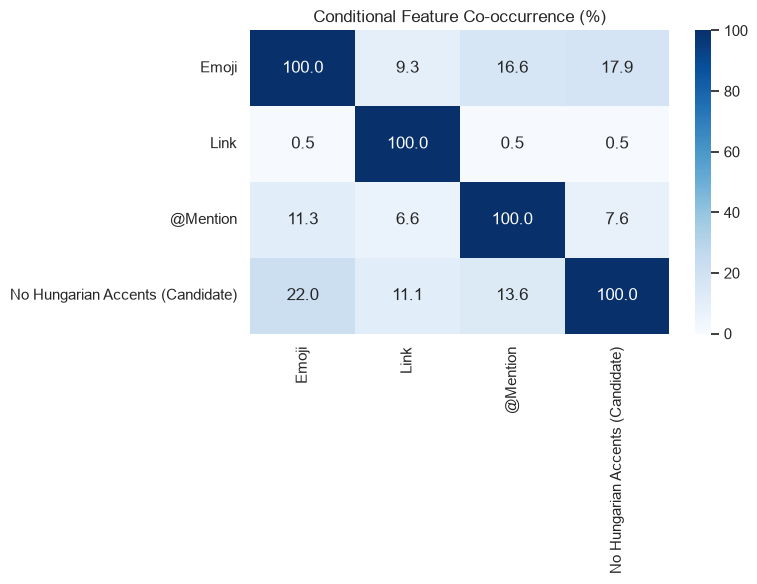

In [12]:
feature_cols = list(features)

cooccurrence = pd.DataFrame(
    {
        feature_a: {
            feature_b: (
                df_features.loc[df_features[feature_a], feature_b].mean() * 100
                if df_features[feature_a].any() else float("nan")
            )
            for feature_b in feature_cols
        }
        for feature_a in feature_cols
    }
)

cooccurrence = cooccurrence.rename(
    index=features,
    columns=features
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cooccurrence,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100
)

plt.title("Conditional Feature Co-occurrence (%)")
plt.tight_layout()
plt.show()

## Adattisztítás

In [13]:
# Angol csatornák kizárása a kommentekből
english_channels = ["TLCVEVO", "Karan Thakur", "BryanAdamsVEVO", "PaulaAbdulVEVO", "Olympics", "matysik44", "Queen Official"]
df_comments = df_comments[~df_comments["channel_title"].isin(english_channels)]
df_comments = df_comments.reset_index(drop=True)

In [16]:
# Magyar emoji-elnevezések letöltése
URL = (
    "https://raw.githubusercontent.com/unicode-org/cldr-json/"
    "main/cldr-json/cldr-annotations-full/"
    "annotations/hu/annotations.json"
)

URL_PATTERN = re.compile(r"https?://\S+|www\.\S+", re.IGNORECASE)
MENTION_PATTERN = re.compile(r"(?<!\w)@[\w.-]+", re.UNICODE)
REPEAT_PATTERN = re.compile(r"(.)\1{2,}", re.UNICODE)

response = requests.get(URL, timeout=30)
response.raise_for_status()

data = response.json()["annotations"]["annotations"]

# Emoji -> magyar elnevezés
emoji_hu = {
    char: info["tts"][0]
    for char, info in data.items()
    if info.get("tts")
}

def replace_emoji_hu(text: str) -> str:
    if not isinstance(text, str):
        return ""

    def replace(char, metadata):
        # Próbáljuk az eredeti alakot, majd
        # a variációs jel nélküli változatot.
        name = (
            emoji_hu.get(char)
            or emoji_hu.get(char.replace("\ufe0f", ""))
        )

        # Ha nincs fordítás, megtartjuk az emojit.
        return f" {name if name else char} "

    result = emoji.replace_emoji(
        text,
        replace=replace
    )

    return re.sub(r"\s+", " ", result).strip()

def clean_text(text, emoji_removal=True):
    REPEAT_PATTERN = re.compile(r"(.)\1{2,}", re.UNICODE)
    text = URL_PATTERN.sub(" urltoken ", text)
    text = MENTION_PATTERN.sub(" mentiontoken ", text)
    text = REPEAT_PATTERN.sub(
        lambda m: m.group(1) * 2, text
    )

    text = re.sub(r"\s+", " ", text).strip()

    if emoji_removal:
        text = emoji.replace_emoji(text, replace="")
    else:
        text = replace_emoji_hu(text)

    return text
    

In [20]:
df_comments["text_clean"] = df_comments["text"].apply(
    lambda x: clean_text(x, emoji_removal=False)
)
df_comments[["text", "text_clean"]].sample(5).head()

,text,text_clean
214292,"Amióta idejárok, rengeteg dolgot tudtam meg:\n...","Amióta idejárok, rengeteg dolgot tudtam meg: -..."
4931,​@BeciToth-zt6vu olvass már utána hogy milyen ...,​ mentiontoken olvass már utána hogy milyen fe...
344578,Annyira örülök hogy Dunaszerdahelyre is jössz ...,Annyira örülök hogy Dunaszerdahelyre is jössz ...
171774,"kapsz szánalmat helyette, tessék","kapsz szánalmat helyette, tessék"
241938,Hogyan nem találkoztam Winkler Róberttel a Boh...,Hogyan nem találkoztam Winkler Róberttel a Boh...


## Szöveg feldolgozás

In [30]:
from tqdm.auto import tqdm

# Mondathatár-felismerés hozzáadása
if not any(p in nlp.pipe_names for p in ["parser", "senter", "sentencizer"]):
    nlp.add_pipe("sentencizer")

print(nlp.pipe_names)

df_clean = df_comments.copy()

sentences = []
tokens = []
sentence_tokens = []

texts = df_clean["text_clean"].fillna("").astype(str)

for doc in tqdm(nlp.pipe(texts, batch_size=64), total=len(texts)):
    # Mondatok
    sentences.append([sent.text.strip() for sent in doc.sents])

    # Tokenek
    tokens.append([token.text for token in doc if not token.is_space])

    # Mondatok tokenjei
    sentence_tokens.append([
        [token.text for token in sent if not token.is_space]
        for sent in doc.sents
    ])

df_clean["sentences"] = sentences
df_clean["tokens"] = tokens
df_clean["sentence_tokens"] = sentence_tokens

display(df_clean[["text_clean", "sentences", "tokens"]].head())

['sentencizer']


  0%|          | 0/458965 [00:00<?, ?it/s]

,text_clean,sentences,tokens
0,Megosztott linkek: 26:25 - Durva buzdító képek...,[Megosztott linkek: 26:25 - Durva buzdító képe...,"[Megosztott, linkek, :, 26:25, -, Durva, buzdí..."
1,Kicsit durva csak. Mint az is hogy sokan az ol...,"[Kicsit durva csak., Mint az is hogy sokan az ...","[Kicsit, durva, csak, ., Mint, az, is, hogy, s..."
2,Talán sikeresebb lehetne az oltás népszerűsíté...,[Talán sikeresebb lehetne az oltás népszerűsít...,"[Talán, sikeresebb, lehetne, az, oltás, népsze..."
3,"mentiontoken jó, de ugye ő konteós laposföldhi...","[mentiontoken jó, de ugye ő konteós laposföldh...","[mentiontoken, jó, ,, de, ugye, ő, konteós, la..."
4,mentiontoken milyen Robi? Szkeptikus kerekaszt...,"[mentiontoken milyen Robi?, Szkeptikus kerekas...","[mentiontoken, milyen, Robi, ?, Szkeptikus, ke..."
